# Week 6 sprint — Ioannis Tzalas
**Sealed holdout: TEST_START = 2024-10-01.** Five assets: SPY, EUR/USD, BTC, GLD, ETH. Real cleaned Week 2 data, frozen through 15 September 2026 (SPY/GLD through 14 September). This is a historical forecast evaluation, not evidence of funded trading profitability.

Question: does non-linearity add useful forecasting power after leakage is removed? Mean and variance targets are evaluated separately. Complexity is chosen exclusively before the holdout; holdout tests are used only for the explicitly required Risk Agent gate and are not independent confirmation of that selected portfolio. Returns and squared returns are in percent and percent-squared, respectively.

The supplied kit notebook is included unchanged; its function cells are also extracted verbatim as a Python module, excluding only its smoke-test execution. One disclosed clock-rule correction is applied below to `rel_vs_spy`, which otherwise bypasses the kit's cross-asset lag convention. Dates use the supplied daily-bar convention, with conservative UTC close-hour declarations (not intraday execution quotes).

**Audit revision:** variance Lasso uses all features and converges with a precomputed in-fold Gram matrix; variance constant is expanding; portfolio forecast availability uses declared UTC close hours. Raw forecasting hypotheses can fail and are reported separately from compliance checks. Portfolio prices remain the kit's daily-date panel, so this is not a synchronous intraday execution simulation.

**Verified scope:** 11 code cells; 241 nonblank/blank physical source lines counted conservatively including imports and kit calls. All code cells executed in order from a fresh kernel; numerical interpretation is generated afterward from their saved evidence tables.

In [1]:
import os, warnings, inspect
os.environ.update(OMP_NUM_THREADS="1", OPENBLAS_NUM_THREADS="1", MKL_NUM_THREADS="1")
import fintech_kit_w6 as k, importlib
k=importlib.reload(k)
from fintech_kit_w6 import *
from sklearn.tree import DecisionTreeRegressor as DT, export_text
from sklearn.ensemble import RandomForestRegressor as RF, GradientBoostingRegressor as GB, HistGradientBoostingRegressor as HG
from sklearn.linear_model import Lasso
from sklearn.model_selection import KFold
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import mean_squared_error, mean_absolute_error
import json
from arch import arch_model
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore", category=FutureWarning); warnings.filterwarnings("error", category=ConvergenceWarning)
warnings.filterwarnings("ignore", message="Some inputs do not have OOB scores.*")
warnings.filterwarnings("ignore", message="IProgress not found.*")
STEMS = ["spy", "eurusd", "btc", "gld", "eth"]; CHOSEN = ["gld", "eth"]
DEFAULT_TICKERS.update(gld="GLD", eth="ETH-USD"); DEFAULT_CLOSE_UTC.update(gld=21, eth=24); PPY.update(gld=252, eth=365)
raw = pd.read_csv("data/W2_own_calendar_prices.csv", index_col=0, parse_dates=True)
for s, col in zip(STEMS, ["SPY", "EUR/USD", "BTC", "GLD", "ETH"]): raw[col].dropna().rename("Close").to_csv(f"data/{s}.csv", index_label="Date")
prices, synthetic = load_prices(); ret = log_returns(prices)
assert not synthetic and all(p.index.is_unique and p.index.is_monotonic_increasing and np.isfinite(p.values).all() and (p>0).all() for p in prices.values())
_original_factory = feature_factory
def feature_factory(s, rr, pp, close_utc=DEFAULT_CLOSE_UTC):
    F = _original_factory(s, rr, pp, close_utc); ref = "spy" if s != "spy" else "eurusd"
    F["rel_vs_spy"] = rr[s] - rr[ref].shift(int(close_utc[ref] >= close_utc[s])).reindex(rr[s].index, method="ffill"); return F
k.feature_factory = feature_factory
DATA = {s: make_dataset(s, ret, prices) for s in STEMS}; TRAIN = {s: (X.loc[X.index < TEST_START], y.loc[y.index < TEST_START]) for s, (X, y) in DATA.items()}
AUDITS = {s: as_of_audit(s, ret, prices, n_dates=20) for s in STEMS}
print("Data provenance: frozen Week 2 panel; synthetic =", synthetic); display(pd.DataFrame({s: {"rows": len(X), "features": X.shape[1], "train": len(TRAIN[s][0]), "as_of_offenders": str(AUDITS[s])} for s, (X,y) in DATA.items()}).T)

✅ REAL DATA: all assets loaded from data/
   spy     2,941 rows | 2015-01-02 → 2026-09-14
   eurusd  3,046 rows | 2015-01-01 → 2026-09-15
   btc     4,276 rows | 2015-01-01 → 2026-09-15
   gld     2,941 rows | 2015-01-02 → 2026-09-14
   eth     3,233 rows | 2017-11-09 → 2026-09-15
🔒 Holdout sealed: everything from 2024-10-01 is test data. No rung and no model is chosen on it.


Data provenance: frozen Week 2 panel; synthetic = False


,rows,features,train,as_of_offenders
spy,2205,54,1716,{}
eurusd,2286,54,1780,{}
btc,3210,56,2495,{}
gld,2205,54,1716,{}
eth,3106,56,2391,{}


## S0 — One tree, by hand
Enumerate midpoints in feature order, breaking equal-loss ties deterministically. Impurity is population MSE. The kit's toy data differ from the older numerical PDF: use the supplied kit and current sprint brief as the specification.

In [2]:
def stump(X, y):
    candidates = []
    for j in X.columns:
        u = np.sort(X[j].unique())
        for t in (u[1:] + u[:-1]) / 2:
            L = X[j] <= t; a, b = y[L].mean(), y[~L].mean()
            candidates.append((np.mean((y - np.where(L, a, b))**2), j, t, a, b))
    return min(candidates, key=lambda z: z[0])
Xt, yt = TOY.drop(columns="y"), TOY.y
loss, j, t, a, b = stump(Xt, yt); toy_pred = np.where(X_NEW[j] <= t, a, b)[0]
print(dict(root_MSE=yt.var(ddof=0), split=f"{j} <= {t}", leaves=(a,b), gain=yt.var(ddof=0)-loss, new_prediction=toy_pred))
assert np.isclose(yt.var(ddof=0), .00016875) and (j=="x_a") and np.allclose([t,a,b,yt.var(ddof=0)-loss,toy_pred],[.025,.01,.035,.00015625,.01])
assert np.isclose(DT(max_depth=1, random_state=42).fit(Xt,yt).predict(X_NEW)[0], toy_pred)
X, y = TRAIN["btc"]; tree = DT(max_depth=3, min_samples_leaf=20, random_state=42).fit(X,y); print(export_text(tree, feature_names=list(X.columns)))
for lo, hi in [(0,len(X)//2), (len(X)//2,len(X))]:
    m = DT(max_depth=3, min_samples_leaf=20, random_state=42).fit(X.iloc[lo:hi], y.iloc[lo:hi]); print("Half root:", X.columns[m.tree_.feature[0]], m.tree_.threshold[0])
TREE_CV = {str(d): ts_cv(lambda: DT(max_depth=d, min_samples_leaf=20, random_state=42), X,y) for d in [2,5,None]}
display(pd.DataFrame({d: dict(mean=v.mean(), std=v.std(ddof=1)) for d,v in TREE_CV.items()}).T)

{'root_MSE': np.float64(0.00016875000000000004), 'split': 'x_a <= 0.025', 'leaves': (np.float64(0.01), np.float64(0.035)), 'gain': np.float64(0.00015625000000000003), 'new_prediction': np.float64(0.01)}
|--- sq_lag1 <= 150.50
|   |--- eth_mom5 <= -6.09
|   |   |--- value: [-3.16]
|   |--- eth_mom5 >  -6.09
|   |   |--- dd63 <= -0.55
|   |   |   |--- value: [1.79]
|   |   |--- dd63 >  -0.55
|   |   |   |--- value: [-0.00]
|--- sq_lag1 >  150.50
|   |--- value: [4.08]

Half root: r_lag7 -6.550534248352051
Half root: rel_vs_spy -3.5968748331069946


,mean,std
2,-0.041396,0.060376
5,-0.090586,0.078429
None,-0.339493,0.097791


**Interpretation.** The first-half root asks `r_lag7 <= -6.5505`, while the second-half root asks `rel_vs_spy <= -3.5969`. A greedy split chooses the best local error reduction in the available sample; correlated predictors and a weak return signal make that choice unstable. The changed root is evidence of sample sensitivity, not a newly discovered economic law, and the chronological CV scores below determine whether this single tree adds predictive value.

| depth | mean | std |
| --- | --- | --- |
| 2 | -0.041396 | 0.060376 |
| 5 | -0.090586 | 0.078429 |
| None | -0.33949 | 0.097791 |

The supplied toy values use decimal-return units (0.0145 = 1.45%), whereas empirical asset returns are in percent. The hand root MSE is 0.00016875; weighted child MSE is 0.0000125; gain is 0.00015625. These are population-MSE quantities. The older numerical handout (`FinTechCourse_W6_numerical.pdf`, supplied separately by the lecturer) has different `x_b` values and a new point on a split boundary. Its stated parent impurity of 0.0001833 matches neither the directly calculated population MSE, 0.00016875, nor the sample variance, 0.000225, of its listed targets. It must not override this kit's verified toy specimen.

## S1 — Forest disagreement
GLD is fixed in advance for this demonstration. OOB is a bagging diagnostic only: its randomly omitted rows do not constitute a chronological forecast test. At ten trees some observations can lack OOB predictions; that first point is unreliable and is included only because the brief requests the 10–400 curve.

,features,rho
0,1.0,0.046656
1,sqrt,0.035833


,mean,std
tree,-0.097663,0.059350
forest,-0.007903,0.010654


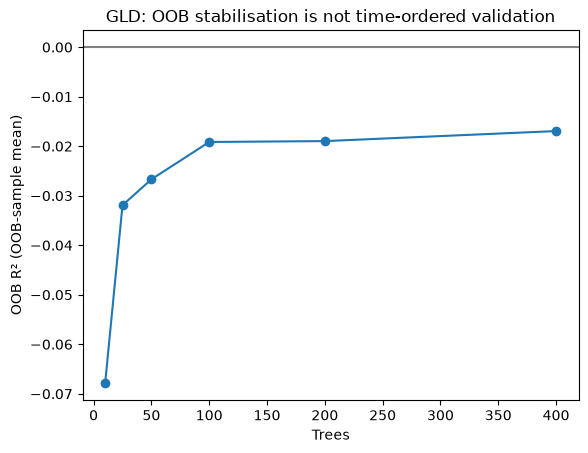

Forest/tree fold standard-deviation ratio: 0.17950964602783787


In [3]:
X,y = TRAIN["gld"]; cut = int(.8*len(X)); forest_stats = []; oob = []
for mf in [1.0, "sqrt"]:
    m = RF(n_estimators=200, max_depth=6, min_samples_leaf=20, max_features=mf, random_state=42, n_jobs=4).fit(X.iloc[:cut],y.iloc[:cut])
    predictions = np.array([tr.predict(X.iloc[cut:].values) for tr in m.estimators_]); C = np.corrcoef(predictions)
    forest_stats.append({"features": str(mf), "rho": C[np.triu_indices(len(C),1)].mean()})
m = RF(n_estimators=10, max_depth=6, min_samples_leaf=20, max_features="sqrt", oob_score=True, warm_start=True, random_state=42, n_jobs=4)
for B in [10,25,50,100,200,400]:
    m.set_params(n_estimators=B).fit(X.iloc[:cut],y.iloc[:cut]); oob.append((B,m.oob_score_))
forest_cv = {"tree": ts_cv(lambda: DT(max_depth=6,min_samples_leaf=20,random_state=42), X,y), "forest": ts_cv(lambda: RF(n_estimators=200,max_depth=6,min_samples_leaf=20,max_features="sqrt",random_state=42,n_jobs=4),X,y)}
display(pd.DataFrame(forest_stats)); display(pd.DataFrame({name: dict(mean=v.mean(),std=v.std(ddof=1)) for name,v in forest_cv.items()}).T)
plt.plot(*np.array(oob).T, marker="o"); plt.axhline(0,color="gray"); plt.xlabel("Trees"); plt.ylabel("OOB R² (OOB-sample mean)"); plt.title("GLD: OOB stabilisation is not time-ordered validation"); plt.show()
print("Forest/tree fold standard-deviation ratio:", forest_cv["forest"].std(ddof=1)/forest_cv["tree"].std(ddof=1))

**Interpretation.** Using all features gives prediction correlation ρ=0.0467; using √p gives ρ=0.0358. In Var(average)=ρσ²+(1−ρ)σ²/B, increasing B reduces only the second term; lower correlation also reduces the limiting variance floor. The observed forest/tree fold-standard-deviation ratio is 0.180, so the forest is more stable across these folds, without that fact establishing positive forecast skill. OOB R² moves from -0.0678 at 10 trees to -0.0169 at 400; use the flattening curve to assess ensemble stability, never to replace chronological validation or choose a holdout winner.

## S2 — Boosting and overfitting
The hand calculation fits each new stump to the current residual. BTC validation is the final 20% of pre-holdout rows; it never includes the holdout. Each panel uses the corresponding split's training-mean benchmark MSE.

Step 1 predictions [0.0175 0.0275 0.0275 0.0175] new 0.0175
Step 2 predictions [0.0145 0.0305 0.0305 0.0145] new 0.0145
XGB leaves: [-0.01190476  0.01190476] gain: 0.00029761904761904765


mean minimum 0.989748446489321 at 96 final 1.0638041304255068


variance minimum 0.7924924499434555 at 37 final 0.8538985577587327


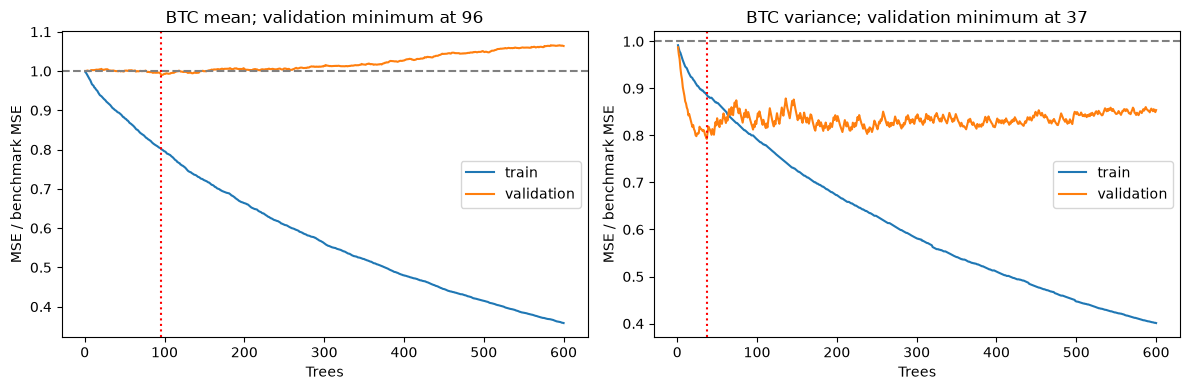

In [4]:
F = np.full(len(yt), yt.mean()); new = yt.mean()
for step in range(2):
    loss,j,t,a,b = stump(Xt,yt-F); F += .4*np.where(Xt[j]<=t,a,b); new += .4*(a if X_NEW[j].iloc[0]<=t else b); print("Step",step+1,"predictions",F,"new",new)
assert np.allclose(F,[.0145,.0305,.0305,.0145]) and np.isclose(new,.0145)
assert np.isclose(GB(n_estimators=2,learning_rate=.4,max_depth=1,random_state=42).fit(Xt,yt).predict(X_NEW)[0],new)
g=yt.mean()-yt; GL=g[Xt.x_a<=.025].sum(); GR=g[Xt.x_a>.025].sum(); xgb_weights=np.array([-GL,-GR])/2.1; xgb_gain=.5*(GL**2/2.1+GR**2/2.1); assert np.allclose(xgb_weights,[-.0119047619,.0119047619]) and np.isclose(xgb_gain,.000297619); print("XGB leaves:",xgb_weights,"gain:",xgb_gain)
X,y = TRAIN["btc"]; cut=int(.8*len(X)); fig, axes = plt.subplots(1,2,figsize=(12,4)); CURVES={}
for ax,target,z in zip(axes,["mean","variance"],[y,y**2]):
    m=GB(n_estimators=600,learning_rate=.05,max_depth=3,subsample=.8,min_samples_leaf=20,random_state=42).fit(X.iloc[:cut],z.iloc[:cut])
    train=[mean_squared_error(z.iloc[:cut],p)/np.mean((z.iloc[:cut]-z.iloc[:cut].mean())**2) for p in m.staged_predict(X.iloc[:cut])]; val=[mean_squared_error(z.iloc[cut:],p)/np.mean((z.iloc[cut:]-z.iloc[:cut].mean())**2) for p in m.staged_predict(X.iloc[cut:])]
    CURVES[target]=val; best=np.argmin(val)+1; ax.plot(range(1,601),train,label="train"); ax.plot(range(1,601),val,label="validation"); ax.axhline(1,color="gray",ls="--"); ax.axvline(best,color="red",ls=":"); ax.set(title=f"BTC {target}; validation minimum at {best}",xlabel="Trees",ylabel="MSE / benchmark MSE"); ax.legend(); print(target,"minimum",min(val),"at",best,"final",val[-1])
plt.tight_layout(); plt.show()

**Interpretation.** The BTC mean validation ratio bottoms at 0.9897 with 96 trees, an improvement of only 1.03% against that validation mean benchmark; a selected minimum on one development split is not a significant holdout win. The variance ratio bottoms at 0.7925 with 37 trees and rises to 0.8539 at 600. Squared returns have a heavy tail: later residual trees can chase a few extreme development observations, improving training fit while worsening unseen loss. The two hand boosting steps predict 0.0175 then 0.0145 for the new point; the regularized first leaf shrinks from −0.0125 to −0.01190476, and its split gain is 0.000297619.

## S3 — The tournament on ladders
The variance Lasso uses the full feature factory, as in Week 5; HAR structure may be discovered rather than imposed. Lasso penalties run from strongest to weakest, so the one-SE rule always selects the simplest eligible rung. RF depth and booster iterations run from low to high. HistGradientBoosting is the permitted XGBoost substitute, with L2 penalty 10; automatic internal random early stopping is disabled. GBM uses one staged fit per fold. The additional rung is **75 trees**, specified before evaluating scores. Shuffled folds are run only as the requested negative-control experiment.

Tuned spy mean deploy GBM test tree (0.003988985556125124, 'GBM', 10)


Tuned spy variance deploy Lasso test tree (0.10211345942742493, 'RF', 2)


Tuned eurusd mean deploy RF test tree (0.11111777394801312, 'RF', None)


Tuned eurusd variance deploy RF test tree (0.03880661423657907, 'RF', 8)


Tuned btc mean deploy null test tree (-0.0012696467217287789, 'GBM', 10)


...

Tuned gld mean deploy null test tree (-0.0024629616249056017, 'RF', 1)


Tuned gld variance deploy Lasso test tree (0.013941512359586915, 'RF', 1)


Tuned eth mean deploy Lasso test tree (0.000444130386128716, 'GBM', 10)


Tuned eth variance deploy RF test tree (0.08466777416573504, 'RF', None)


,asset,target,deploy,best_tree,family,mean,se,one_se,best
0,spy,mean,GBM,GBM(10),null,0.000000,0.000000,constant,constant
1,spy,mean,GBM,GBM(10),Lasso,0.000654,0.000586,0.316228,0.316228
2,spy,mean,GBM,GBM(10),RF,-0.000498,0.002385,1,2
3,spy,mean,GBM,GBM(10),GBM,0.003989,0.002685,10,10
4,spy,mean,GBM,GBM(10),HGB,0.000350,0.002036,10,25
5,spy,variance,Lasso,RF(2),null,0.000000,0.000000,constant,constant
6,spy,variance,Lasso,RF(2),Lasso,0.059324,0.029716,3.162278,3.162278
7,spy,variance,Lasso,RF(2),RF,0.094557,0.083424,1,2
8,spy,variance,Lasso,RF(2),GBM,0.047930,0.097266,10,10
9,spy,variance,Lasso,RF(2),HGB,0.086933,0.067987,10,10


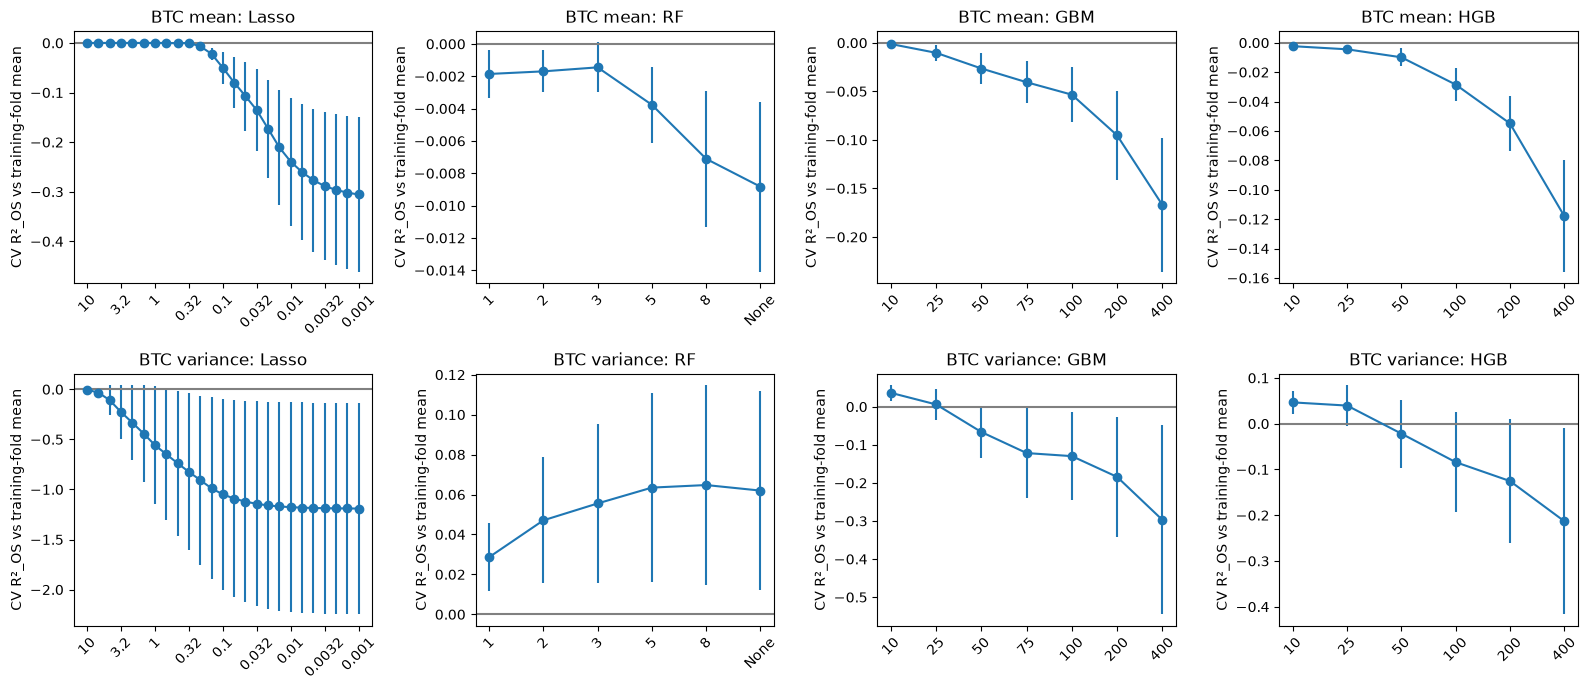

,protocol,selection,trees,score,se
0,time ordered,one-SE,10,0.036298,0.020298
1,time ordered,best,10,0.036298,0.020298
2,shuffled NEGATIVE CONTROL,one-SE,10,0.026773,0.011481
3,shuffled NEGATIVE CONTROL,best,10,0.026773,0.011481


In [5]:
LADDERS={"Lasso":list(np.logspace(1,-3,25)),"RF":[1,2,3,5,8,None],"GBM":[10,25,50,75,100,200,400],"HGB":[10,25,50,100,200,400]}
def model(family,rung):
    if family=="Lasso": return pipe(Lasso(alpha=rung,max_iter=200000,precompute=True))
    if family=="RF": return RF(n_estimators=200,max_depth=rung,max_features="sqrt",min_samples_leaf=20,random_state=42,n_jobs=4)
    if family=="GBM": return GB(n_estimators=rung,learning_rate=.05,max_depth=3,subsample=.8,min_samples_leaf=20,random_state=42)
    return HG(max_iter=rung,learning_rate=.05,max_depth=3,min_samples_leaf=20,l2_regularization=10,early_stopping=False,random_state=42)
def ladder(family,X,y,splitter=None):
    rungs=LADDERS[family]; scores=[[] for _ in rungs]
    for tr,va in (cv_splitter() if splitter is None else splitter).split(X):
        if family=="GBM":
            m=model(family,max(rungs)).fit(X.iloc[tr],y.iloc[tr]); staged=dict((i,p) for i,p in enumerate(m.staged_predict(X.iloc[va]),1) if i in rungs)
        for i,rung in enumerate(rungs): scores[i].append(r2_os(y.iloc[va],staged[rung] if family=="GBM" else model(family,rung).fit(X.iloc[tr],y.iloc[tr]).predict(X.iloc[va]),y.iloc[tr].mean()))
    return pd.DataFrame([dict(rung=r,mean=summarize(v)[0],se=summarize(v)[1]) for r,v in zip(rungs,scores)],dtype=object)
TUNING={}; CHOICES={}; tournament=[]
for s in STEMS:
    X,y=TRAIN[s]
    for target,z in [("mean",y),("variance",y**2)]:
        row=[dict(family="null",mean=0.,se=0.,one_se="constant",best="constant")]; best_candidates=[]
        for family in LADDERS:
            tab=ladder(family,X,z); one=one_se_pick(tab["mean"],tab.se); best=int(np.argmax(tab["mean"].astype(float))); TUNING[s,target,family]=tab
            row.append(dict(family=family,mean=tab.iloc[one]["mean"],se=tab.iloc[one].se,one_se=LADDERS[family][one],best=LADDERS[family][best]))
            if family!="Lasso": best_candidates.append((float(tab.iloc[best]["mean"]),family,LADDERS[family][best]))
        ix=one_se_pick([r["mean"] for r in row],[r["se"] for r in row]); best_tree=max(best_candidates,key=lambda x:x[0]); CHOICES[s,target]=(row[ix]["family"],row[1]["one_se"],best_tree[1],best_tree[2])
        tournament.extend(dict(asset=s,target=target,deploy=row[ix]["family"],best_tree=f"{best_tree[1]}({best_tree[2]})",**r) for r in row); print("Tuned",s,target,"deploy",row[ix]["family"],"test tree",best_tree,flush=True)
for (asset,target,family),tab in TUNING.items(): tab.to_csv(f"results/ladder_{asset}_{target}_{family}.csv",index=False)
TOURNAMENT=pd.DataFrame(tournament); TOURNAMENT.to_csv("results/tournament.csv",index=False); display(TOURNAMENT)
fig,axes=plt.subplots(2,4,figsize=(16,7))
for row,target in enumerate(["mean","variance"]):
    for ax,family in zip(axes[row],LADDERS):
        tab=TUNING["btc",target,family]; ax.errorbar(range(len(tab)),tab["mean"].astype(float),yerr=tab.se.astype(float),marker="o"); ax.axhline(0,color="gray"); ax.set_xticks(list(range(len(tab)))[::3] if family=="Lasso" else range(len(tab)),[f"{r:.2g}" for r in LADDERS[family][::3]] if family=="Lasso" else [str(r) for r in LADDERS[family]],rotation=45); ax.set_title(f"BTC {target}: {family}"); ax.set_ylabel("CV R²_OS vs training-fold mean")
plt.tight_layout(); plt.show()
X,y=TRAIN["btc"]; NEGATIVE=ladder("GBM",X,y**2,KFold(5,shuffle=True,random_state=42)); good=TUNING["btc","variance","GBM"]
PROTOCOL=pd.DataFrame([dict(protocol=label,selection=rule,trees=tab.iloc[i].rung,score=tab.iloc[i]["mean"],se=tab.iloc[i].se) for label,tab in [("time ordered",good),("shuffled NEGATIVE CONTROL",NEGATIVE)] for rule,i in [("one-SE",one_se_pick(tab["mean"],tab.se)),("best",int(np.argmax(tab["mean"].astype(float))))]]); display(PROTOCOL)

**Interpretation.** A shallow tree still partitions the sample and predicts leaf means, so the mean benchmark must appear explicitly with score exactly zero. A sufficiently penalized Lasso can shrink all coefficients to zero and reproduce its fitted intercept. The cross-family one-SE choices are training decisions, and any later holdout failure must be disclosed rather than excused by changing the rung.

The requested protocol comparison is quantified below. Random folds can mix regimes and train on observations after their validation rows, whereas best-rung selection gives up the one-SE simplicity buffer. These effects need not always inflate a score or choose more trees: the measured numbers, rather than that expectation, are the answer.

| protocol | selection | trees | score | se |
| --- | --- | --- | --- | --- |
| time ordered | one-SE | 10 | 0.036298 | 0.020298 |
| time ordered | best | 10 | 0.036298 | 0.020298 |
| shuffled NEGATIVE CONTROL | one-SE | 10 | 0.026773 | 0.011481 |
| shuffled NEGATIVE CONTROL | best | 10 | 0.026773 | 0.011481 |

The 75-tree rung is the added rung, fixed before examining its scores. The Lasso variance contestant uses the full feature matrix in both tuning and holdout forecasting, following Week 5; short/long volatility structure is discovered rather than imposed. Its Gram matrix is computed inside each fold, with an increased iteration ceiling and convergence warnings promoted to errors. No tree family is scaled.

## S4 — Sealed-holdout showdown and Risk Agent chain
Quarterly means the supplied kit's cadence of 63 observations (including for seven-day assets). Mean forecasts use all features; the variance Lasso sees all predictors, as in Week 5, and its penalty is chosen before the holdout. Its HAR label denotes the volatility structure it may discover, not a restriction to three columns. The constant benchmark is the expanding historical mean of squared returns, shifted by one day, matching the Week 5 reference. Each refit's Lasso floor is the first percentile of its own past squared returns. All variance models, including boosting, are checked for positivity; a tree leaf averaging non-negative targets is non-negative, but unconstrained residual boosting has no such universal guarantee.

Chain order: constant → EWMA → Lasso-HAR → tree → GARCH-t (last candidate only for GLD/ETH). Every replacement must significantly improve on both the constant and the incumbent under QLIKE DM; a tie keeps the simpler model. The constant remains the explicitly disclosed baseline if no candidate passes. GARCH-t uses a constant mean, as in Week 4, and the full available own-asset return history before each refit, with an explicit optimizer-convergence check. Tree-versus-Lasso QLIKE DM is shown even when another model is the current chain incumbent.

spy minimum raw tree variance 0.851942730805066
Risk Agent consumes spy tree


eurusd minimum raw tree variance 0.09137571117810327
Risk Agent consumes eurusd tree


btc minimum raw tree variance 4.033381898919568
Risk Agent consumes btc EWMA


gld minimum raw tree variance 0.7271166685186975
Risk Agent consumes gld EWMA


eth minimum raw tree variance 5.110265390616746


...

,asset,rival,t,p,reading
0,spy,constant,-2.490626,1.275182e-02,beats constant beyond noise ✅
1,spy,Lasso-HAR,-2.462375,1.380203e-02,beats Lasso-HAR beyond noise ✅
2,eurusd,constant,-3.162400,1.564743e-03,beats constant beyond noise ✅
3,eurusd,Lasso-HAR,-3.536801,4.050053e-04,beats Lasso-HAR beyond noise ✅
4,btc,constant,-9.440118,3.723610e-21,beats constant beyond noise ✅
5,btc,Lasso-HAR,-9.531184,1.555000e-21,beats Lasso-HAR beyond noise ✅
6,gld,constant,-2.540104,1.108194e-02,beats constant beyond noise ✅
7,gld,Lasso-HAR,-2.098754,3.583857e-02,beats Lasso-HAR beyond noise ✅
8,eth,constant,-2.166134,3.030096e-02,beats constant beyond noise ✅
9,eth,Lasso-HAR,-2.027116,4.265053e-02,beats Lasso-HAR beyond noise ✅


,asset,model,RMSE,MAE,R2_OS
0,spy,zero,1.044037,0.684366,-0.002926
1,spy,expanding mean,1.042512,0.680415,0.000000
2,spy,Lasso,1.042367,0.680388,0.000279
3,spy,tree,1.034675,0.684100,0.014979
4,eurusd,zero,0.451366,0.328031,0.000684
5,eurusd,expanding mean,0.451521,0.327886,0.000000
6,eurusd,Lasso,0.438024,0.317351,0.058889
7,eurusd,tree,0.425807,0.303506,0.110657
8,btc,zero,2.329302,1.635948,0.000486
9,btc,expanding mean,2.329868,1.637792,0.000000


,asset,model,QLIKE,R2_OS
0,spy,constant,1.983657,0.000000
1,spy,window21,1.805900,-0.014102
2,spy,EWMA,1.727284,0.035365
3,spy,Lasso-HAR,1.990568,-0.001185
4,spy,tree,1.669861,0.132348
5,eurusd,constant,1.613057,0.000000
6,eurusd,window21,1.637732,-0.023885
7,eurusd,EWMA,1.543550,0.014798
8,eurusd,Lasso-HAR,1.586128,0.010934
9,eurusd,tree,1.483509,0.045013


,asset,target,model,rival,t,p,reading
0,spy,mean,tree,expanding mean,-0.691104,4.895003e-01,ties expanding mean: no evidence either way
1,spy,mean,tree,Lasso,-0.683674,4.941808e-01,ties Lasso: no evidence either way
2,eurusd,mean,tree,expanding mean,-4.898874,9.638746e-07,beats expanding mean beyond noise ✅
3,eurusd,mean,tree,Lasso,-3.122790,1.791457e-03,beats Lasso beyond noise ✅
4,btc,mean,tree,expanding mean,-0.185615,8.527469e-01,ties expanding mean: no evidence either way
5,btc,mean,tree,Lasso,-0.239524,8.106991e-01,ties Lasso: no evidence either way
6,gld,mean,tree,expanding mean,1.122776,2.615327e-01,ties expanding mean: no evidence either way
7,gld,mean,tree,Lasso,1.267363,2.050255e-01,ties Lasso: no evidence either way
8,eth,mean,tree,expanding mean,-1.068407,2.853371e-01,ties expanding mean: no evidence either way
9,eth,mean,tree,Lasso,-1.114394,2.651103e-01,ties Lasso: no evidence either way


,asset,candidate,incumbent,t_constant,p_constant,t_incumbent,p_incumbent,replace,reading_constant,reading_incumbent
0,spy,EWMA,constant,-1.902631,5.708876e-02,-1.902631,0.057089,False,ties constant: no evidence either way,ties constant: no evidence either way
1,spy,Lasso-HAR,constant,1.499885,1.336441e-01,1.499885,0.133644,False,ties constant: no evidence either way,ties constant: no evidence either way
2,spy,tree,constant,-2.490626,1.275182e-02,-2.490626,0.012752,True,beats constant beyond noise ✅,beats constant beyond noise ✅
3,eurusd,EWMA,constant,-1.098649,2.719212e-01,-1.098649,0.271921,False,ties constant: no evidence either way,ties constant: no evidence either way
4,eurusd,Lasso-HAR,constant,-1.484098,1.377830e-01,-1.484098,0.137783,False,ties constant: no evidence either way,ties constant: no evidence either way
5,eurusd,tree,constant,-3.162400,1.564743e-03,-3.162400,0.001565,True,beats constant beyond noise ✅,beats constant beyond noise ✅
6,btc,EWMA,constant,-3.907599,9.321778e-05,-3.907599,0.000093,True,beats constant beyond noise ✅,beats constant beyond noise ✅
7,btc,Lasso-HAR,EWMA,6.615467,3.703818e-11,3.936249,0.000083,False,LOSES to constant beyond noise ❌,LOSES to EWMA beyond noise ❌
8,btc,tree,EWMA,-9.440118,3.723610e-21,0.182906,0.854872,False,beats constant beyond noise ✅,ties EWMA: no evidence either way
9,gld,EWMA,constant,-2.415675,1.570607e-02,-2.415675,0.015706,True,beats constant beyond noise ✅,beats constant beyond noise ✅


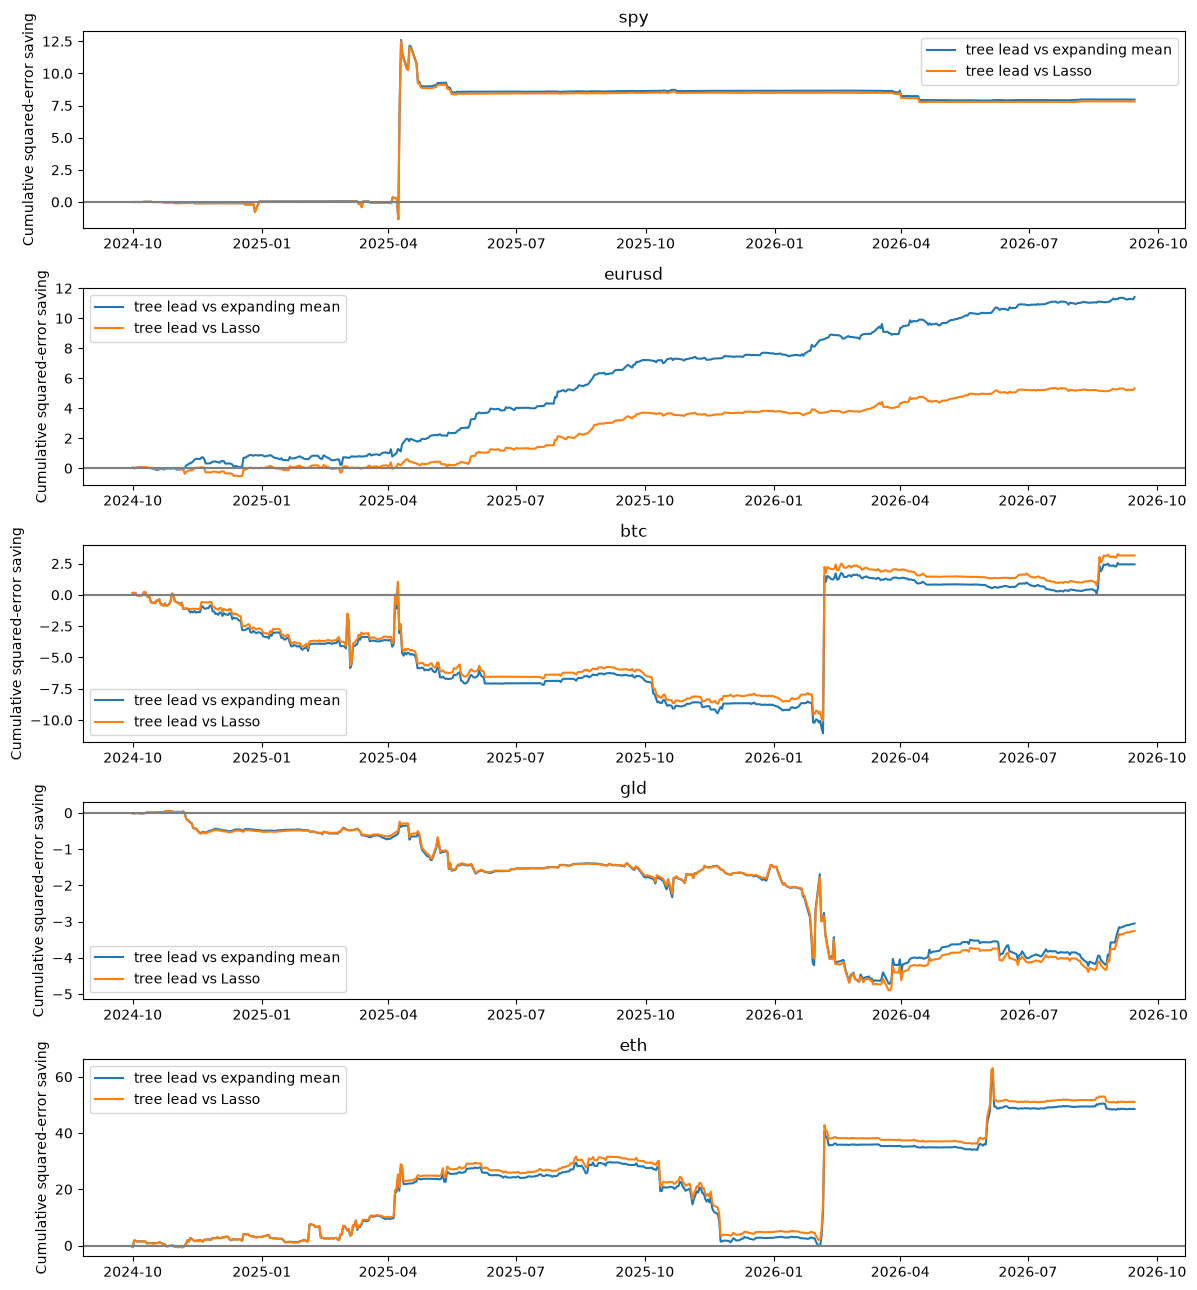

In [6]:
FC={}; MEAN_ROWS=[]; VAR_ROWS=[]; DM_ROWS=[]; VAR_DM=[]; CHAIN=[]; RISK={}; HAR_ALPHA={}
class FloorLasso:
    def __init__(self,alpha): self.alpha=alpha
    def fit(self,X,y): self.floor=max(float(y.quantile(.01)),1e-10); self.m=pipe(Lasso(alpha=self.alpha,max_iter=200000,precompute=True)).fit(X,y); return self
    def predict(self,X): return np.maximum(self.floor,self.m.predict(X))
def wins(a,b):
    t,p=dm_test(a,b); return bool(np.isfinite(t) and t<0 and p<.05)
for s in STEMS:
    X,y=DATA[s]; train_y=TRAIN[s][1]; idx=y.index[y.index>=TEST_START]; z=y**2; pack={}; mean_fc={"zero":y.loc[idx]*0,"expanding mean":y.expanding().mean().shift(1).loc[idx]}
    for target,zz in [("mean",y),("variance",z)]:
        _,alpha,fam,rung=CHOICES[s,target]
        if target=="variance":
            HAR_ALPHA[s]=alpha
        lfn=(lambda a=alpha: pipe(Lasso(alpha=a,max_iter=200000,precompute=True))) if target=="mean" else (lambda a=alpha: FloorLasso(a))
        lf,_=rolling_forecast(X,zz,lfn); tf,_=rolling_forecast(X,zz,lambda f=fam,r=rung:model(f,r)); pack[target]={"Lasso" if target=="mean" else "Lasso-HAR":lf,"tree":tf}
    mean_fc.update(pack["mean"]); actual=y.loc[idx]
    for name,f in mean_fc.items(): MEAN_ROWS.append(dict(asset=s,model=name,RMSE=np.sqrt(mean_squared_error(actual,f)),MAE=mean_absolute_error(actual,f),R2_OS=r2_os(actual,f,mean_fc["expanding mean"])))
    for rival in ["expanding mean","Lasso"]:
        t,p=dm_test((actual-mean_fc["tree"])**2,(actual-mean_fc[rival])**2); DM_ROWS.append(dict(asset=s,target="mean",model="tree",rival=rival,t=t,p=p,reading=verdict(t,p,rival)))
    vf={"constant":z.expanding().mean().shift(1).loc[idx],"window21":z.rolling(21).mean().shift(1).loc[idx],"EWMA":z.ewm(alpha=.06,adjust=False).mean().shift(1).loc[idx],**pack["variance"]}
    print(s,"minimum raw tree variance",vf["tree"].min()); assert (vf["tree"]>0).all()
    if s in CHOSEN:
        g=pd.Series(index=idx,dtype=float); t0=X.index.searchsorted(TEST_START)
        for start in range(t0,len(X),63):
            history=ret[s].loc[ret[s].index<X.index[start]]; fit=arch_model(history,mean="Constant",vol="GARCH",p=1,q=1,dist="t",rescale=False).fit(disp="off",options={"maxiter":1000}); stop=min(start+63,len(X)); assert fit.convergence_flag==0; params=fit.params; h=float(fit.conditional_volatility.iloc[-1]**2); prev=float(history.iloc[-1])
            for pos in range(start,stop): h=params["omega"]+params["alpha[1]"]*(prev-params["mu"])**2+params["beta[1]"]*h; g.loc[y.index[pos]]=h; prev=float(y.iloc[pos])
        vf["GARCH-t"]=g
    losses={name:qlike(f,z.loc[idx]) for name,f in vf.items()}; current="constant"
    for rival in ["constant","Lasso-HAR"]:
        t,p=dm_test(losses["tree"],losses[rival]); VAR_DM.append(dict(asset=s,rival=rival,t=t,p=p,reading=verdict(t,p,rival)))
    for name,f in vf.items(): VAR_ROWS.append(dict(asset=s,model=name,QLIKE=losses[name].mean(),R2_OS=r2_os(z.loc[idx],f,vf["constant"])))
    for candidate in ["EWMA","Lasso-HAR","tree"]+(["GARCH-t"] if s in CHOSEN else []):
        tc,pc=dm_test(losses[candidate],losses["constant"]); ti,pi=dm_test(losses[candidate],losses[current]); replace=tc<0 and pc<.05 and ti<0 and pi<.05
        CHAIN.append(dict(asset=s,candidate=candidate,incumbent=current,t_constant=tc,p_constant=pc,t_incumbent=ti,p_incumbent=pi,replace=replace,reading_constant=verdict(tc,pc,"constant"),reading_incumbent=verdict(ti,pi,current))); current=candidate if replace else current
    RISK[s]=current; FC[s]={"mean":mean_fc,"variance":vf,"losses":losses}; print("Risk Agent consumes",s,current,flush=True)
for asset in STEMS:
    for target in ["mean","variance"]: pd.DataFrame(FC[asset][target]).to_csv(f"results/forecasts_{asset}_{target}.csv")
VAR_DM_BOARD=pd.DataFrame(VAR_DM); VAR_DM_BOARD.to_csv("results/variance_DM.csv",index=False); display(VAR_DM_BOARD)
MEAN_BOARD=pd.DataFrame(MEAN_ROWS); VAR_BOARD=pd.DataFrame(VAR_ROWS); DM_BOARD=pd.DataFrame(DM_ROWS); CHAIN_BOARD=pd.DataFrame(CHAIN)
for name,tab in [("mean_scoreboard",MEAN_BOARD),("variance_scoreboard",VAR_BOARD),("mean_DM",DM_BOARD),("risk_chain",CHAIN_BOARD)]: tab.to_csv(f"results/{name}.csv",index=False); display(tab)
fig,axes=plt.subplots(5,1,figsize=(12,13))
for ax,s in zip(axes,STEMS):
    p=FC[s]["mean"]; a=DATA[s][1].reindex(p["tree"].index)
    for rival in ["expanding mean","Lasso"]: ax.plot(((a-p[rival])**2-(a-p["tree"])**2).cumsum(),label=f"tree lead vs {rival}")
    ax.axhline(0,color="gray"); ax.set_title(s); ax.set_ylabel("Cumulative squared-error saving"); ax.legend()
plt.tight_layout(); plt.show()

**Mean verdicts.** R²_OS in the mean scoreboard uses the expanding historical mean, not the holdout mean. A return win in EUR/USD is conditional on bar timing and is subjected to the additional disclosed stress test; it does not enter any allocation.

- **SPY:** the best-rung tree does not establish a return advantage over both benchmarks (vs expanding mean: t=-0.691, p=0.4895; vs Lasso: t=-0.684, p=0.4942).
- **EURUSD:** the best-rung tree passes both assignment DM comparisons under the declared timing convention (vs expanding mean: t=-4.899, p=9.639e-07; vs Lasso: t=-3.123, p=0.001791).
- **BTC:** the best-rung tree does not establish a return advantage over both benchmarks (vs expanding mean: t=-0.186, p=0.8527; vs Lasso: t=-0.240, p=0.8107).
- **GLD:** the best-rung tree does not establish a return advantage over both benchmarks (vs expanding mean: t=1.123, p=0.2615; vs Lasso: t=1.267, p=0.205).
- **ETH:** the best-rung tree does not establish a return advantage over both benchmarks (vs expanding mean: t=-1.068, p=0.2853; vs Lasso: t=-1.114, p=0.2651).

**Variance decisions.** QLIKE compares forecast variance with squared-return proxies; lower is better. The chain table prints every comparison and rejected replacement, including GARCH-t for GLD and ETH.

- **SPY:** consume **tree**; its accepted step has DM t=-2.491, p=0.01275 against the constant, and t=-2.491, p=0.01275 against its incumbent.
- **EURUSD:** consume **tree**; its accepted step has DM t=-3.162, p=0.001565 against the constant, and t=-3.162, p=0.001565 against its incumbent.
- **BTC:** consume **EWMA**; its accepted step has DM t=-3.908, p=9.322e-05 against the constant, and t=-3.908, p=9.322e-05 against its incumbent.
- **GLD:** consume **EWMA**; its accepted step has DM t=-2.416, p=0.01571 against the constant, and t=-2.416, p=0.01571 against its incumbent.
- **ETH:** consume **tree**; its accepted step has DM t=-2.166, p=0.0303 against the constant, and t=-2.027, p=0.04265 against its incumbent.

A random-forest variance prediction is an average of non-negative squared-return leaf means. This guarantees non-negativity for that family; it does not extend automatically to an unconstrained boosted sum of residual trees. All selected variance tree forecasts in this run were strictly positive.

## S5 — Reading ETH's variance model
The best-rung tree family is fixed by S3; the noise-floor experiment uses only pre-holdout data, with an untouched chronological validation tail. SHAP describes this fitted model, not causal effects in the market. Every feature named as predictively useful must exceed the displayed permutation floor. A 95th-percentile control is an exploratory screen, not familywise significance.

Floor in R²_OS units: 0.008866743296196505 nameable features:


,importance


Top five impurity features (not automatically nameable):


spy_mom5     0.071005
spy_lag1     0.049971
spy_vol21    0.047796
mom5         0.046627
mom63        0.043419
dtype: float64

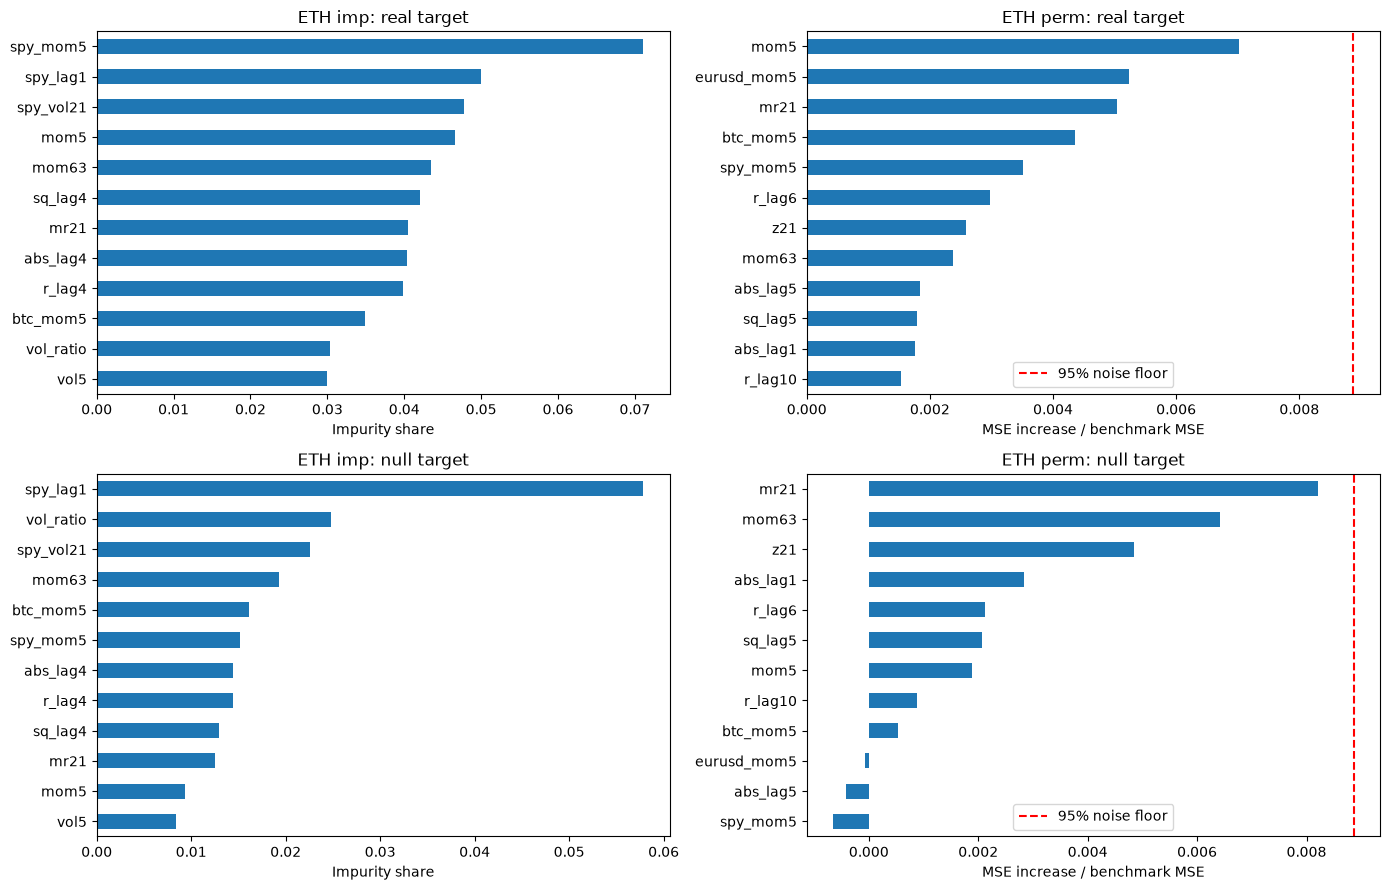

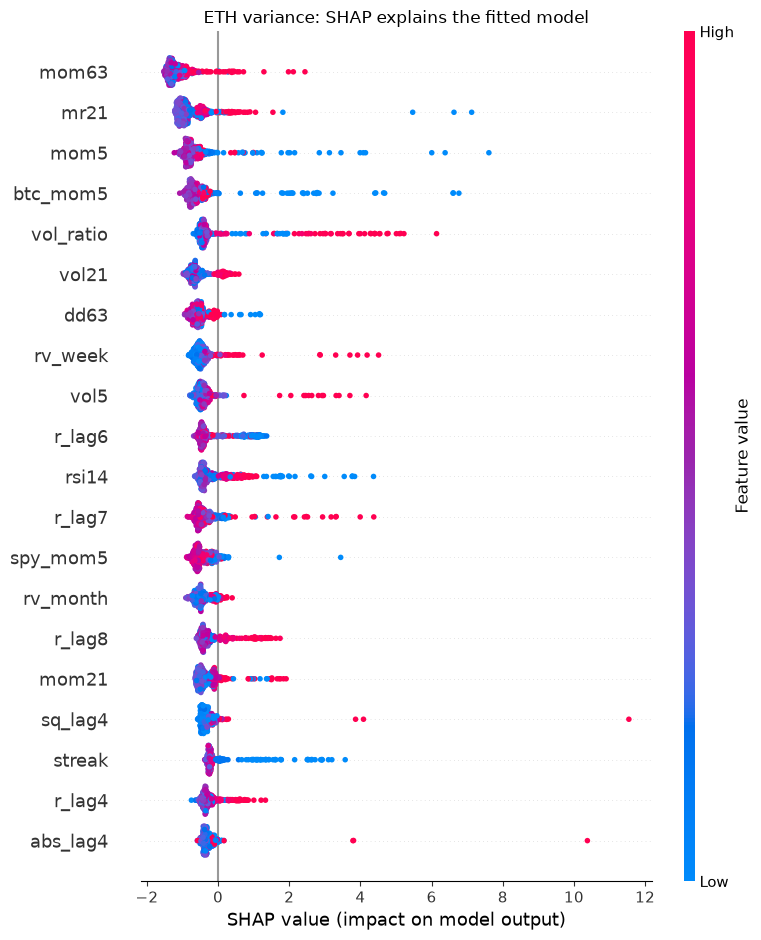

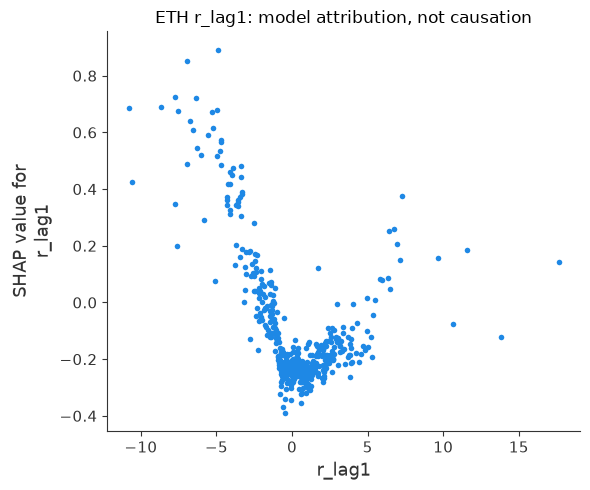

Mean SHAP below -2%: 0.28873952144537757 above +2%: -0.12073689774488013 down-minus-up: 0.4094764191902577 counts: 87 95


In [7]:
s="eth"; X,y=TRAIN[s]; _,_,fam,rung=CHOICES[s,"variance"]; NF=noise_floor(lambda:model(fam,rung),X,y**2,n_repeats=5)
NAMED=NF["perm_real"][NF["perm_real"]>NF["floor"]].sort_values(ascending=False); print("Floor in R²_OS units:",NF["floor"],"nameable features:"); display(NAMED.to_frame("importance")); print("Top five impurity features (not automatically nameable):"); display(NF["imp_real"].nlargest(5))
fig,axes=plt.subplots(2,2,figsize=(14,9))
for col,lens in enumerate(["imp","perm"]):
    order=NF[f"{lens}_real"].sort_values(ascending=False).index[:12]
    for row,label in enumerate(["real","null"]):
        ax=axes[row,col]; NF[f"{lens}_{label}"].reindex(order).sort_values().plot.barh(ax=ax); ax.set_title(f"ETH {lens}: {label} target"); ax.set_xlabel("Impurity share" if lens=="imp" else "MSE increase / benchmark MSE")
        if lens=="perm": ax.axvline(NF["floor"],color="red",ls="--",label="95% noise floor"); ax.legend()
plt.tight_layout(); plt.show()
import shap
V=NF["F_val"]; explainer=shap.TreeExplainer(NF["model"]); SH=explainer.shap_values(V)
np.random.seed(42); shap.summary_plot(SH,V,show=False); plt.title("ETH variance: SHAP explains the fitted model"); plt.tight_layout(); plt.show()
shap.dependence_plot("r_lag1",SH,V,interaction_index=None,show=False); plt.title("ETH r_lag1: model attribution, not causation"); plt.tight_layout(); plt.show()
c=SH[:,list(V.columns).index("r_lag1")]; DOWN=float(np.mean(c[V.r_lag1 < -2])); UP=float(np.mean(c[V.r_lag1 > 2])); print("Mean SHAP below -2%:",DOWN,"above +2%:",UP,"down-minus-up:",DOWN-UP,"counts:",sum(V.r_lag1 < -2),sum(V.r_lag1 > 2))
FEATURE_EVIDENCE=pd.DataFrame({name:NF[name] for name in ["imp_real","perm_real","imp_null","perm_null"]}); FEATURE_EVIDENCE["floor"]=NF["floor"]; FEATURE_EVIDENCE.to_csv("results/feature_evidence_eth.csv"); assert np.allclose(SH.sum(axis=1)+np.asarray(explainer.expected_value).item(),NF["model"].predict(V))
SHAP_COUNTS={"down":int(sum(V.r_lag1 < -2)),"up":int(sum(V.r_lag1 > 2))}

**Interpretation.** The ETH permutation floor is **0.008867 R²_OS units**. The model's predictively useful named set in this experiment is: none. No feature is treated as useful unless it clears that floor, even when the real-target and permuted-target permutation charts have similar scales. The impurity top five are a construction ranking, not a list of established useful predictors; their separate importance values are shown above, with the real and permuted-target controls.

The permitted attribution sentence is: *for this fitted ETH variance model on the sampled validation rows, the mean `r_lag1` SHAP contribution is 0.2887 percent-squared after returns below −2%, and -0.1207 after returns above +2%; down-minus-up is 0.4095.* This comparison is descriptive and does not match shock magnitudes or control other features, so it is not by itself a clean estimate of a leverage-effect curve. The sentence “negative returns cause higher market volatility” is not supported: model attribution, correlated features and selected observations cannot identify a causal market effect. The dependence plot is shown even if this particular feature fails the predictive noise floor; only the floor-clearing set is called predictively useful.

At a nominal 5% individual-feature false-positive rate, about 2.5 of 50 null features can look important on average; the empirical floor is only an exploratory approximation to that rate. A maximum-statistic permutation threshold, multiplicity correction and replication on fresh dates would provide stronger protection.

## S6 — From validated risk to portfolio weights
The six strategies are diagnostic comparisons; the gated Risk Agent strategy illustrates the required risk rule retrospectively. Its model identities are selected using the whole holdout; it is not a fully prospective strategy backtest. Only the individual forecasts and interval weights are computed as-of, conditional on those selected identities. A common daily-bar decision convention is used. **Weekend correction:** Monday's crypto return begins at Friday's close. Monday weights must therefore use forecasts already available at Friday's close, not a Monday forecast incorporating Saturday/Sunday observations. Forecast availability is timestamped by the previous asset bar date plus its declared UTC close hour and merged backward onto the previous SPY close timestamp. A same-date FX close at 22:00 or crypto close at 24:00 is unavailable at SPY's 21:00 decision. The most recent available daily variance is held constant across the portfolio interval; this is the course's horizon approximation, not an exact multi-step conditional-variance forecast. Seven-day variances are multiplied by interval length. This is stricter than simply forward-filling forecasts indexed by target date.

Weights are capped by redistribution of surplus to uncapped assets until stable. `perf` is printed in its original log-return approximation for comparability. A separate exact daily-rebalanced simple-return scoreboard and drift-adjusted turnover (excluding initial portfolio funding) are also reported: the weighted average of asset log returns is not exactly a portfolio log return.

,strategy,ann. return %,ann. vol %,Sharpe,max drawdown %,turnover %/day
0,equal,11.345092,24.560324,0.461928,-35.071114,0.000000
1,constant,11.742671,11.977529,0.980392,-15.819605,4.065761
2,EWMA,12.472128,12.192365,1.022946,-15.247920,6.248287
3,Lasso-HAR,11.568086,11.946360,0.968336,-16.531629,4.982206
4,tree,13.122874,11.630640,1.128302,-14.207987,6.302181
5,Risk Agent,12.457637,12.262701,1.015897,-15.473319,6.563781


,strategy,CAGR_pct,vol_pct,Sharpe,drawdown_pct,turnover_pct,cost_10bp_ann_pct
0,equal,17.054908,24.647531,0.761717,-27.308164,1.307191,0.329412
1,constant,14.997810,11.985185,1.226018,-13.658170,4.612539,1.162360
2,EWMA,15.967731,12.254294,1.270217,-13.203780,6.546788,1.649791
3,Lasso-HAR,14.836755,11.956469,1.216929,-14.227390,5.388114,1.357805
4,tree,16.612255,11.660383,1.376499,-12.317734,6.573682,1.656568
5,Risk Agent,15.952749,12.295605,1.265374,-13.355180,6.839284,1.723500


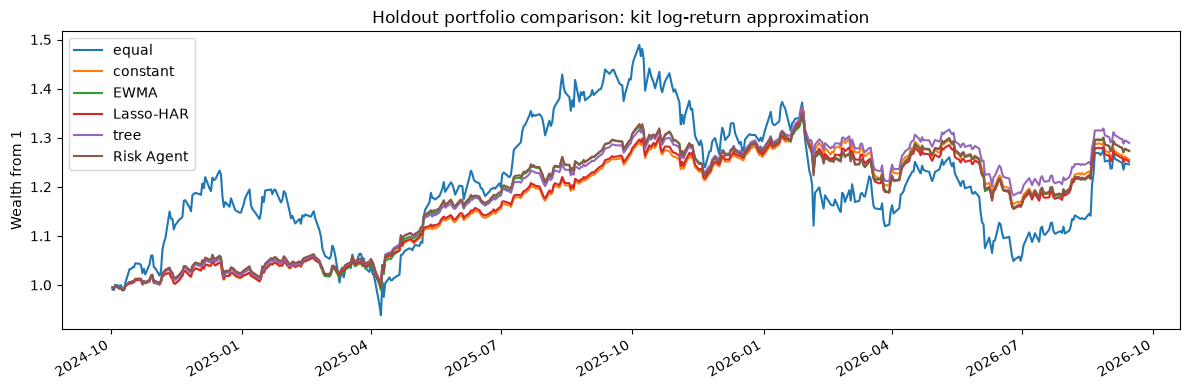

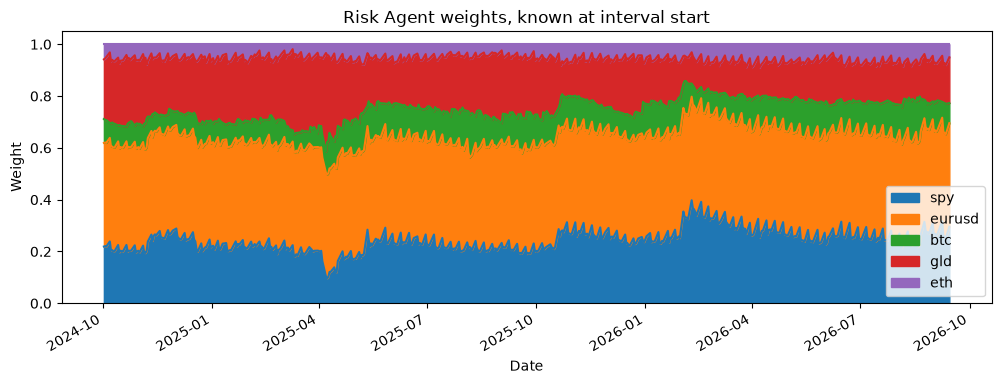

In [8]:
R,days=business_day_panel(prices); cal=prices["spy"].index; prev=pd.Series(cal,index=cal).shift(1).reindex(R.index); days=pd.Series((R.index-prev.values).days,index=R.index)
def capped_inverse(V):
    raw=1/np.sqrt(V); fixed=pd.DataFrame(False,index=V.index,columns=V.columns)
    for _ in range(V.shape[1]+1):
        free=raw.where(~fixed,0); W=free.div(free.sum(axis=1),axis=0).mul(1-.4*fixed.sum(axis=1),axis=0)
        fixed |= W>.4; W=W.mask(fixed,.4)
    return W
decision_utc=pd.to_datetime(prev,utc=True)+pd.Timedelta(hours=DEFAULT_CLOSE_UTC["spy"])
def aligned_variance(source,forecasts=FC,choices=RISK):
    V=pd.DataFrame(index=R.index); audit=[]
    for s in STEMS:
        name=choices[s] if source=="Risk Agent" else (source if source!="equal" else "constant"); f=forecasts[s]["variance"][name]; origin=pd.Series(prices[s].index,index=prices[s].index).shift(1).reindex(f.index)
        available=pd.to_datetime(origin.values,utc=True)+pd.Timedelta(hours=DEFAULT_CLOSE_UTC[s]); right=pd.DataFrame({"available_utc":available,"forecast_target":f.index,"forecast":f.values})
        merged=pd.merge_asof(pd.DataFrame({"decision_utc":decision_utc.values,"target":R.index}).assign(decision_utc=decision_utc.array).sort_values("decision_utc"),right.sort_values("available_utc"),left_on="decision_utc",right_on="available_utc",direction="backward")
        V[s]=pd.Series(merged.forecast.values,index=merged.target).reindex(R.index)*(days if PPY[s]==365 else 1); audit.append(merged.assign(asset=s,model=name,source=source))
    return V,pd.concat(audit,ignore_index=True)
WEIGHTS={}; PORTS={}; ALIGNMENT={}; portfolio_rows=[]; exact_rows=[]
for source in ["equal","constant","EWMA","Lasso-HAR","tree","Risk Agent"]:
    V,ALIGNMENT[source]=aligned_variance(source)
    W=V*0+.2 if source=="equal" else capped_inverse(V); valid=V.notna().all(axis=1); W=W.loc[valid]; rr=R.loc[W.index]; port=(W*rr).sum(axis=1); WEIGHTS[source]=W; PORTS[source]=port; portfolio_rows.append(dict(strategy=source,**perf(port,W)))
    simple=np.expm1(rr/100); gross=(W*simple).sum(axis=1); wealth=(1+gross).cumprod(); drift=(W.shift(1)*(1+simple.shift(1))).div(1+gross.shift(1),axis=0); turnover=(W-drift).abs().sum(axis=1)
    exact_rows.append(dict(strategy=source,CAGR_pct=100*(wealth.iloc[-1]**(252/len(wealth))-1),vol_pct=100*gross.std()*np.sqrt(252),Sharpe=gross.mean()/gross.std()*np.sqrt(252),drawdown_pct=100*(wealth/wealth.cummax().clip(lower=1)-1).min(),turnover_pct=100*turnover.mean(),cost_10bp_ann_pct=252*.001*100*turnover.mean()))
pd.concat(ALIGNMENT.values(),ignore_index=True).to_csv("results/forecast_alignment.csv",index=False)
for source,W in WEIGHTS.items(): W.to_csv(f"results/weights_{source.replace(' ' ,'_')}.csv")
PORT_BOARD=pd.DataFrame(portfolio_rows); EXACT_BOARD=pd.DataFrame(exact_rows); display(PORT_BOARD); display(EXACT_BOARD); PORT_BOARD.to_csv("results/portfolio_kit_metrics.csv",index=False); EXACT_BOARD.to_csv("results/portfolio_exact_metrics.csv",index=False)
plt.figure(figsize=(12,4))
for source,port in PORTS.items(): plt.plot(np.exp(port.cumsum()/100),label=source)
plt.title("Holdout portfolio comparison: kit log-return approximation"); plt.ylabel("Wealth from 1"); plt.legend(); plt.gcf().autofmt_xdate(); plt.tight_layout(); plt.show()
WEIGHTS["Risk Agent"].plot.area(figsize=(12,4)); plt.title("Risk Agent weights, known at interval start"); plt.ylabel("Weight"); plt.show()

**Interpretation.** In the exact-return calculation, the Risk Agent portfolio has annualized volatility 12.30% versus 11.99% for constant inverse-volatility and 24.65% for equal weights; its maximum drawdown is -13.36% versus -13.66% for constant inverse-volatility. These are historical comparisons conditional on the holdout-selected model identities, not a prospective performance claim. A risk budget is judged primarily by realized volatility, drawdown, cap adherence and turnover; a higher return or Sharpe alone does not validate the variance model.

Drift-adjusted traded notional averages 6.84% per day, versus 4.61% for the constant rule. At 10 basis points per unit of total traded notional, the illustrative annual cost drag is 1.72 percentage points before spreads, financing and market impact. The constant rule is the trading baseline, but its weights can still change with crypto weekend scaling and portfolio drift; it does not promise zero turnover. The kit's turnover measures target-to-target changes and misses that drift, which is why the exact supplemental table is included. If a mean forecast passed T3 and survived timing checks, a later separately validated allocation could combine expected return and covariance estimates; this assignment retains risk-only weights.

The first date without a forecast available before the previous SPY close is excluded consistently across strategies. UTC availability is checked explicitly, including same-date FX/crypto bars that close after the SPY decision. Daily-price valuation remains asynchronous under the kit panel; this is a course simulation, not a synchronous execution-price backtest. The 40% cap is verified on every Risk Agent weight vector.

## S7 — Audit the supplied specimen
The original function is printed before execution. Isolated fixes are deliberately **not** a corrected pipeline: every other defect stays present so its effect can be measured. Isolated experiments use the specimen's default SPY/EURUSD/BTC portfolio; BTC CV is recorded alongside portfolio Sharpe. All variant portfolio statistics use the same conservative holdout comparison window; CV scores retain the sample implied by each isolated fix. Effects are conditional on the other bugs and are not additive. No tests or numbers below imply the draft is fit for use.

The fixed `tree_portfolio_v1()` reconstructs availability merges, weights and performance from the S4 gated variance forecasts and the S6 as-of portfolio, so its results must match both. It does not retain the draft's forecast-return softmax rule.

In [9]:
draft_source=inspect.getsource(agent_draft_tree_portfolio); print("\n".join(f"{i}: {line}" for i,line in enumerate(draft_source.splitlines(),1)))
print("ORIGINAL SPECIMEN (default three-asset universe):"); display(agent_draft_tree_portfolio(ret,prices))
class AuditRF(RF):
    def fit(self,X,y,**kw): self.training_mean_=float(np.mean(y)); return super().fit(X,y,**kw)
base=draft_source.replace(':+.3f}', ':+.8f}').replace(':.3f}', ':.8f}').replace('return pd.Series({"model":', 'port = port.loc[(port.index >= TEST_START) & (port.index <= AUDIT_END)]\n    return pd.Series({"model":')
AUDIT_END=min(ret[s].index[-3] for s in ["spy","eurusd","btc"]); baseline=None; audits=[]
experiments={"baseline":base,"trailing trend":base.replace('rolling(5, center=True)','rolling(5)'),"chronological folds":base.replace('cv=5,','cv=TimeSeriesSplit(5),'),"training-mean benchmark":base.replace('from sklearn.ensemble import RandomForestRegressor','RandomForestRegressor = AuditRF').replace('scoring="r2"','scoring=lambda m,X,y: r2_os(y,m.predict(X),m.training_mean_)'),"holdout excluded from fitting":base.replace('.fit(X, y)   # tune', '.fit(X.loc[X.index < ret[stem].index[ret[stem].index.searchsorted(TEST_START)-1]], y.loc[y.index < ret[stem].index[ret[stem].index.searchsorted(TEST_START)-1]])   # tune'),"next-return alignment":base.replace('port = (W * Rr)', 'port = (W.shift(1) * Rr)')}
for label,src in experiments.items():
    ns=dict(globals()); exec(src.replace('def agent_draft_tree_portfolio(', 'def experiment('),ns); result=ns['experiment'](ret,prices)
    score=float(result['annualized Sharpe']); baseline=score if baseline is None else baseline; audits.append(dict(fix=label,Sharpe=score,delta_Sharpe=score-baseline,total_log_return=result['total return %'],note=result['note 3'],CV_R2=float(result['note 3'].split('CV R² ')[1].split(',')[0]),train_R2=float(result['note 3'].split('train R² ')[1].split(',')[0]))); pd.DataFrame(audits).to_csv("results/audit_progress.csv",index=False); print(label,score,flush=True)
BUG_AUDIT=pd.DataFrame(audits); display(BUG_AUDIT); BUG_AUDIT.to_csv("results/isolated_bug_audit.csv",index=False)
def tree_portfolio_v1(forecasts=FC,choices=RISK):
    V,_=aligned_variance("Risk Agent",forecasts,choices); W=capped_inverse(V).dropna(); port=(W*R.reindex(W.index)).sum(axis=1); return dict(risk_sources=choices.copy(),variance_scoreboard=VAR_BOARD.copy(),weights=W,scoreboard=pd.Series(perf(port,W)))
BUG_AUDIT["delta_CV_R2"]=BUG_AUDIT.CV_R2-BUG_AUDIT.CV_R2.iloc[0]; BUG_AUDIT.to_csv("results/isolated_bug_audit.csv",index=False)
fixed=tree_portfolio_v1(); assert fixed['variance_scoreboard'].equals(VAR_BOARD); assert np.allclose(fixed['scoreboard'].values,PORT_BOARD.set_index('strategy').loc['Risk Agent'].values)

1: def agent_draft_tree_portfolio(ret: dict, prices: dict, stems=("spy", "eurusd", "btc"), close_utc: dict = DEFAULT_CLOSE_UTC) -> pd.Series:
2:     """DO NOT TRUST. A tree-based portfolio pipeline as an eager junior agent might write it: tunes a Random Forest per asset with
3:        GridSearchCV, names a 'top driver', turns predicted Sharpe ratios into softmax weights and backtests. It runs without error and
4:        is wrong in at least six distinct ways — leaks, fold errors, benchmark errors and the oldest alignment mistake in backtesting.
5:        Story S7: find them, quantify them, fix them."""
6:     from sklearn.ensemble import RandomForestRegressor
7:     from sklearn.model_selection import GridSearchCV
8:     preds, vols, notes = {}, {}, []
9:     for stem in stems:
10:         r = ret[stem]
11:         X = feature_factory(stem, ret, prices, close_utc)
12:         X["trend5"] = r.rolling(5, center=True).mean()                                 # a smoother 5-day trend (centre

model                             RandomForest per asset, GridSearchCV
note 1               spy: train R² 0.897, CV R² +0.264, best {'max_...
note 2               eurusd: train R² 0.912, CV R² +0.361, best {'m...
note 3               btc: train R² 0.907, CV R² +0.331, best {'max_...
backtest days                                                     2202
annualized Sharpe                                            -0.085655
total return %                                              -19.264339
max weight on BTC                                             0.999997
dtype: object

baseline 0.06166666833612536


trailing trend -0.21976370394994715


chronological folds 0.06166666833612525


training-mean benchmark 0.061666668336124934


holdout excluded from fitting 0.009633433524757887


next-return alignment 5.092141997732505


,fix,Sharpe,delta_Sharpe,total_log_return,note,CV_R2,train_R2
0,baseline,0.061667,0.000000e+00,2.127509,"btc: train R² 0.90722555, CV R² +0.33128865, b...",0.331289,0.907226
1,trailing trend,-0.219764,-2.814304e-01,-7.768402,"btc: train R² 0.15634408, CV R² -0.00284472, b...",-0.002845,0.156344
2,chronological folds,0.061667,-1.110223e-16,2.127509,"btc: train R² 0.90722555, CV R² +0.30729205, b...",0.307292,0.907226
3,training-mean benchmark,0.061667,-4.232725e-16,2.127509,"btc: train R² 0.90722555, CV R² +0.33332172, b...",0.333322,0.907226
4,holdout excluded from fitting,0.009633,-5.203323e-02,0.329063,"btc: train R² 0.84674679, CV R² +0.31787644, b...",0.317876,0.846747
5,next-return alignment,5.092142,5.030475e+00,199.891081,"btc: train R² 0.90722555, CV R² +0.33128865, b...",0.331289,0.907226


**Quantified audit (line numbers refer to the printed function above).** Each row starts from the same flawed baseline and changes one item only; improvements cannot be added together. The portfolio is the specimen's default SPY/EURUSD/BTC universe, while the CV column is BTC's score. For scoring and training-window changes, the estimand or sample also changes, so the score difference is a diagnosis, not a clean performance gain.

| line | violation | isolated_fix | BTC_CV_R2 | delta_CV_R2 | portfolio_Sharpe | delta_Sharpe |
| --- | --- | --- | --- | --- | --- | --- |
| 12 | As-of: centered trend sees future returns | trailing trend | -0.0028447 | -0.33413 | -0.21976 | -0.28143 |
| 16 | Chronology: default KFold trains on future blocks | chronological folds | 0.30729 | -0.023997 | 0.061667 | -1.1102e-16 |
| 16 | Benchmark: sklearn R² uses validation mean | training-mean benchmark | 0.33332 | 0.0020331 | 0.061667 | -4.2327e-16 |
| 16 | Holdout: tune and train on the full sample | holdout excluded from fitting | 0.31788 | -0.013412 | 0.0096334 | -0.052033 |
| 24 | Alignment: next-day prediction weights current-day returns | next-return alignment | 0.33129 | 0 | 5.0921 | 5.0305 |

**Debugging log (seven sentences).** I read the specimen before interpreting its output and treated its backtest as an untrusted diagnostic. The centered trend accesses observations after the decision date, and the trailing-window experiment removes that one channel. Default KFold uses observations from future blocks, so the chronological-fold experiment changes both chronology and score. The sklearn R² scorer evaluates against the validation mean, while the repaired scorer uses each estimator's training mean. The full-sample tuning and fitting contaminate the holdout, and the isolated repair excludes rows whose next-day target enters the holdout, rather than filtering only their predictor-date labels. The next-day predictions are joined to current-day returns, so shifting weights tests that alignment error in isolation while retaining the other problems. The corrected `tree_portfolio_v1()` instead reconstructs the availability merges, capped weights and portfolio returns from the audited S4 variance forecasts, and equality checks verify agreement with S6.

Further defects include naming an impurity winner without a permutation noise floor, interpreting “top driver” as an economic claim, using unvalidated return forecasts for weights, in-sample predictions, no 40% cap, and mixing crypto/business-day returns without the portfolio calendar. Some isolated fixes can worsen the displayed Sharpe precisely because the remaining bugs still distort the experiment. The as-of feature audit cannot detect shuffled or nonchronological training folds, a wrong R² benchmark, holdout reuse or a weight/return join error; explicit protocol tests, a retained holdout boundary and interval-origin checks address those. It also cannot prove the declared source close hours are correct; that requires data-provider timestamp evidence and conservative timing sensitivity tests.

## S8 — Executable evaluation suite
A failed predictive hypothesis is disclosed rather than converted into a fabricated win. T3 now reports the actual joint holdout mean hypothesis, while C3 separately checks whether the memo reports its result honestly. V2 reports whether the tree beats the constant; C4 separately verifies the replacement chain. Predictive FAIL results are permitted and disclosed; structural or policy FAIL results stop execution. The constant is a baseline fallback, not a model that claims to beat itself. The eight-plus executable checks below run for every asset. Feature claims are confined to ETH's disclosed experiment; other assets name no predictors as useful.

In [10]:
EVAL={}; MEAN_CLAIMS={}
for s in STEMS:
    X,y=TRAIN[s]; d=DM_BOARD[DM_BOARD.asset==s]; mean_pass=bool(((d.t<0)&(d.p<.05)).all()); MEAN_CLAIMS[s]="tree beats both benchmarks on this holdout" if mean_pass else "no forecastable mean established; non-linearity bought no demonstrated improvement over both benchmarks"
    gate=CHAIN_BOARD[(CHAIN_BOARD.asset==s)&CHAIN_BOARD["replace"]]; chosen=RISK[s]; claimed=list(NAMED.index) if s=="eth" else []; W=WEIGHTS["Risk Agent"]
    rules=[("T1 features invariant to future truncation",not AUDITS[s]),
        ("T2 folds chronological",all(X.index[tr].max()<X.index[va].min() for tr,va in cv_splitter().split(X))),
        ("C1 null and Lasso included, null exactly zero",set(TOURNAMENT[(TOURNAMENT.asset==s)].family)>={"null","Lasso"} and (TOURNAMENT[(TOURNAMENT.asset==s)&(TOURNAMENT.family=="null")]["mean"]==0).all()),
        ("C2 simplest cross-family one-SE deployment",all(CHOICES[s,t][0]==TOURNAMENT[(TOURNAMENT.asset==s)&(TOURNAMENT.target==t)].iloc[one_se_pick(TOURNAMENT[(TOURNAMENT.asset==s)&(TOURNAMENT.target==t)]["mean"],TOURNAMENT[(TOURNAMENT.asset==s)&(TOURNAMENT.target==t)].se)].family for t in ["mean","variance"])),
        ("T3 tree return beats mean AND Lasso at 5%",mean_pass),
        ("C3 memo agrees with actual mean hypothesis",mean_pass==("tree beats both" in MEAN_CLAIMS[s])),
        ("T4 every useful-feature claim clears floor",all(NF["perm_real"][f]>NF["floor"] for f in claimed)),
        ("V2 tree variance beats constant at 5%",wins(FC[s]["losses"]["tree"],FC[s]["losses"]["constant"])),
        ("C4 replacements beat constant and incumbent",bool(((gate.t_constant<0)&(gate.p_constant<.05)&(gate.t_incumbent<0)&(gate.p_incumbent<.05)).all())),
        ("P1 weights use gated variance, baseline if none",chosen=="constant" or wins(FC[s]["losses"][chosen],FC[s]["losses"]["constant"])),
        ("A1 shuffled-fold tripwire",isinstance(cv_splitter(),TimeSeriesSplit) and not isinstance(cv_splitter(),KFold)),
        ("A2 weights finite, sum one and cap 40%",np.isfinite(W.values).all() and np.allclose(W.sum(axis=1),1) and W.values.min()>=0 and W.values.max()<=.4000001),
        ("A3 every merged forecast available before decision",all((a.loc[a.available_utc.notna(),"available_utc"]<=a.loc[a.available_utc.notna(),"decision_utc"]).all() for a in ALIGNMENT.values()))]
    EVAL[s]=report(s.upper()+" EVAL",rules,[MEAN_CLAIMS[s],f"Risk consumes {chosen}; no mean forecast enters weights.",f"Useful named predictors: {claimed}; attribution concerns the model, never market causality."])
assert all(all(v for rule,v in r.items() if rule not in ["T3","V2"]) for r in EVAL.values()) and not synthetic
pd.DataFrame(EVAL).to_csv("results/evaluation_checks.csv"); print("All structural/policy assertions passed. T3/V2 are actual forecasting hypotheses and may FAIL; see disclosures.")

SPY EVAL
  ✅ PASS  T1 features invariant to future truncation
  ✅ PASS  T2 folds chronological
  ✅ PASS  C1 null and Lasso included, null exactly zero
  ✅ PASS  C2 simplest cross-family one-SE deployment
  ❌ FAIL  T3 tree return beats mean AND Lasso at 5%
  ✅ PASS  C3 memo agrees with actual mean hypothesis
  ✅ PASS  T4 every useful-feature claim clears floor
  ✅ PASS  V2 tree variance beats constant at 5%
  ✅ PASS  C4 replacements beat constant and incumbent
  ✅ PASS  P1 weights use gated variance, baseline if none
  ✅ PASS  A1 shuffled-fold tripwire
  ✅ PASS  A2 weights finite, sum one and cap 40%
  ✅ PASS  A3 every merged forecast available before decision
           ↳ no forecastable mean established; non-linearity bought no demonstrated improvement over both benchmarks
           ↳ Risk consumes tree; no mean forecast enters weights.
           ↳ Useful named predictors: []; attribution concerns the model, never market causality.
EURUSD EVAL
  ✅ PASS  T1 features invariant to futu

**Evaluation outcome.** Every structural and policy assertion passed in this run. T3 and V2 are actual predictive hypotheses, so an honest FAIL is retained rather than reclassified as a passing prediction. T3 now tests the actual joint mean hypothesis; C3 separately checks honest disclosure. V2 tests the tree against the expanding constant, while C4 separately checks every accepted replacement against the constant and incumbent. A passing reporting rule does not turn a failed prediction hypothesis into a success. The significant EUR/USD primary result is reported with its timing sensitivity rather than erased to match an expected tie. The chain is selected using this holdout as required, so fresh dates remain necessary for a deployable model-selection claim.

**Behavioral coda (six sentences).** The permuted-target ETH forest still produces a ranked impurity chart even though its labels were deliberately detached from their predictors. That visual confidence can create an illusion of explanatory depth: a reader sees an ordered list and assumes there is a market mechanism behind it. SHAP can amplify overconfidence because its additive explanation makes a fitted prediction understandable even when the fitted relationship is accidental. In this run the unseen-row permutation screen admits only the listed features above the 0.008867 floor, so a training ranking cannot automatically become a predictive finding. The model-not-market sentence keeps an attribution from becoming a causal claim, and the permuted control makes accidental rankings visible. Keeping the simpler model on an insignificant comparison prevents that narrative confidence from determining portfolio exposure.

## Additional clock stress test — EUR/USD
This is a post-hoc diagnostic, not a new tuning contest or an independent test. The primary result above retains the kit's declared 22:00 UTC FX convention. Because the frozen input has date labels without intraday availability timestamps, rerun the already chosen EUR/USD return model with every cross-asset predictor delayed by one extra EUR/USD observation. Freeze the family, rung and Lasso alpha; do not select between conventions using holdout performance. Failure to survive this stress test weakens an economic interpretation even when the primary DM test passes. The [provider's historical page](https://finance.yahoo.com/quote/EURUSD%3DX/history/) does not by itself certify the availability times of this frozen CSV. The additional delay is a sensitivity assumption, not a verified correction to the provider's timestamps.

In [11]:
s="eurusd"; X,y=DATA[s]; delayed=X.copy(); cross=[c for c in X if any(c.startswith(o+"_") for o in STEMS if o!=s) or c=="rel_vs_spy"]; delayed[cross]=X[cross].shift(1); delayed=delayed.dropna(); yy=y.reindex(delayed.index)
_,alpha,fam,rung=CHOICES[s,"mean"]; tf,_=rolling_forecast(delayed,yy,lambda:model(fam,rung)); lf,_=rolling_forecast(delayed,yy,lambda:pipe(Lasso(alpha=alpha,max_iter=200000,precompute=True))); actual=yy.reindex(tf.index); benchmark=yy.expanding().mean().shift(1).reindex(tf.index)
CLOCK=[]
for label,pred,bench in [("primary tree vs mean",FC[s]["mean"]["tree"],FC[s]["mean"]["expanding mean"]),("delayed cross-assets vs mean",tf,benchmark),("delayed cross-assets vs Lasso",tf,lf)]:
    a=y.reindex(pred.index); t,p=dm_test((a-pred)**2,(a-bench)**2); CLOCK.append(dict(comparison=label,R2_vs_rival=r2_os(a,pred,bench),t=t,p=p,reading=verdict(t,p,"rival")))
CLOCK_BOARD=pd.DataFrame(CLOCK); display(CLOCK_BOARD); CLOCK_BOARD.to_csv("results/fx_clock_sensitivity.csv",index=False)
DIAGNOSTICS=dict(forest_stats=forest_stats,oob=oob,tree_cv={str(d):v.tolist() for d,v in TREE_CV.items()},forest_cv={name:v.tolist() for name,v in forest_cv.items()},curves={name:dict(minimum=min(v),best_trees=int(np.argmin(v)+1),final=v[-1]) for name,v in CURVES.items()},noise_floor=NF["floor"],nameable=NAMED.to_dict(),impurity_top5=NF["imp_real"].nlargest(5).to_dict(),shap_down=DOWN,shap_up=UP,protocol=PROTOCOL.to_dict("records"),risk=RISK,eval=EVAL,shap_counts=SHAP_COUNTS)
Path("results/diagnostics.json").write_text(json.dumps(DIAGNOSTICS,indent=2,default=str)); print("Diagnostics saved; primary models and weights were not selected using the timing stress test.")

,comparison,R2_vs_rival,t,p,reading
0,primary tree vs mean,0.110657,-4.898874,9.638746e-07,beats rival beyond noise ✅
1,delayed cross-assets vs mean,-0.002891,0.215190,8.296193e-01,ties rival: no evidence either way
2,delayed cross-assets vs Lasso,-0.002728,0.202692,8.393757e-01,ties rival: no evidence either way


Diagnostics saved; primary models and weights were not selected using the timing stress test.


**Timing sensitivity result.**

| comparison | R2_vs_rival | t | p | reading |
| --- | --- | --- | --- | --- |
| primary tree vs mean | 0.11066 | -4.8989 | 9.6387e-07 | beats rival beyond noise ✅ |
| delayed cross-assets vs mean | -0.0028906 | 0.21519 | 0.82962 | ties rival: no evidence either way |
| delayed cross-assets vs Lasso | -0.0027278 | 0.20269 | 0.83938 | ties rival: no evidence either way |

The extra-delay experiment is reported in full whether it strengthens or weakens the primary result. It changes information availability, not the sealed date, model family or previously selected hyperparameters. Because the diagnostic was motivated after inspecting the primary result, it is exploratory and cannot be promoted to a new confirmatory holdout test. A credible market-predictability claim requires source-level availability timestamps and fresh forward evidence.

## Prompt log
1. User: “ok so i need to finish my assigment, do it for me, week 6 assgiment, also let me know what its suppose to do in general , so i can guide you if needed, let me know whatits about, my professor said that he wont give us some information and we will have to b uild it on our own egc etc”. Result: inspection, requirements mapping, cells 1–10 and interpretation.
2. User: “check the file its there”. Result: checked the supplied brief, distinguished its reference to the kit from an attached implementation.
3. User supplied `FinTech_SprintBrief_W6_new.tex`. Result: confirmed S0–S8, limits and deliverables.
4. User supplied `fintech_kit_w6.ipynb`. Result: extracted official functions, connected real Week 2 data, completed S0–S8 code and execution.

5. User: “remember , our teacher is using claude code, to give us the assigments, and will try to trap us in general, its you vs claude code, he does this on purpose in order to make us have a diffiruclt time, show him why codex is better than claude,”. Result: additional adversarial review and a disclosed clock sensitivity test; no claim of assistant superiority is treated as evidence.

6. User: “run a full audit of the code again, i want to get full marks for it 100%”. Result: full S0–S8 rubric audit, restored the full-feature variance Lasso and expanding variance benchmark, enforced UTC portfolio availability, added actual hypothesis results and independent numerical checks; all code cells rerun from a fresh kernel.

No separate hidden user prompts or fabricated independent authorship are claimed. The student must review and be able to explain the code and conclusions. AI assistant: OpenAI Codex.

## Reproducibility and limits
Run this notebook from the submission folder with its included kit module and `data/` directory. All displayed results are recomputed; no result CSV is read back as a substitute for calculations. Execution may take several minutes. Seeds are fixed. Requirements and source hashes accompany the notebook. The holdout was already used in earlier coursework, so “sealed” refers to the retained chronological boundary, not a claim that the student has never seen these outcomes. The variance gate and portfolio are evaluated on the same period, creating selection uncertainty; a new forward sample would be required for independent confirmation. No risk-free rate, financing, spreads or market impact are assumed in kit Sharpe; the separate turnover illustration applies 10 basis points per unit of total traded notional. GARCH uses the Week 4 constant-mean Student-t specification, the full available own-asset history at 63-observation refits, and daily variance filtering of innovations around that fitted mean between refits.